# Usar el promedio para tomar decisiones

## Escenario Mediocristán

In [ ]:
import numpy as np
import pandas as pd
import math
import matplotlib.pyplot as plt

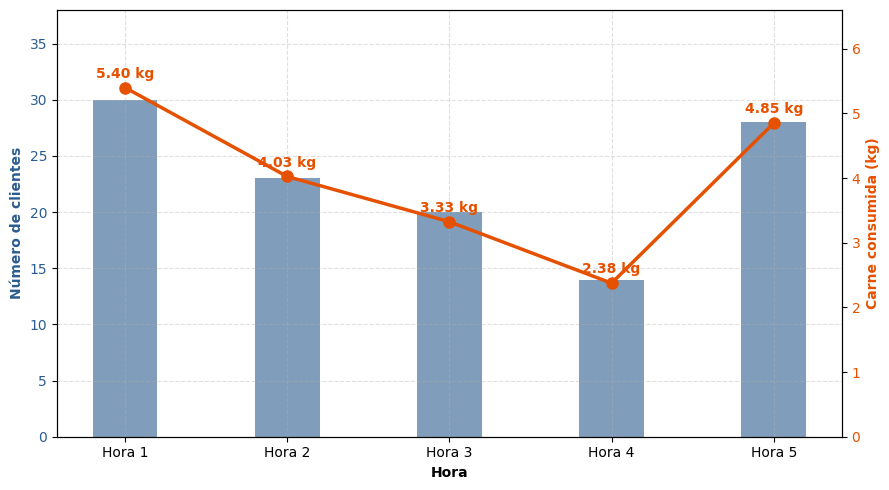

In [ ]:
np.random.seed(101)

# ==========================================
# 1. PARÁMETROS DE LA HAMBURGUESERÍA
# ==========================================
g_clasica = 125
premium = 200
doble_carne = g_clasica * 2  # 250 gramos
consumo = [g_clasica, premium, doble_carne]
p_hamburguer = [0.5, 0.3, 0.2]

horas_al_dia = 5

# ==========================================
# 2. SIMULACIÓN DE UN DÍA (HORA POR HORA)
# ==========================================
clientes_por_hora = []
consumo_por_hora_kg = []

for hora in range(horas_al_dia):
    # Clientes que llegan en esta hora
    n_cli = int(np.random.normal(loc=20, scale=5, size=1)[0])
    n_cli = max(0, n_cli)  # Evitar números negativos
    n_cli = min(30, n_cli)  # Capacidad máxima del establecimiento
    clientes_por_hora.append(n_cli)

    # Consumo generado por los clientes de esta hora
    if n_cli > 0:
        consumo_actual = np.random.choice(consumo, p=p_hamburguer, size=n_cli)
        consumo_kg = consumo_actual.sum() / 1000.0
    else:
        consumo_kg = 0.0

    consumo_por_hora_kg.append(consumo_kg)

# ==========================================
# 3. GRÁFICO DE UN DÍA CON DOBLE EJE Y
# ==========================================
horas_etiquetas = [f'Hora {i+1}' for i in range(horas_al_dia)]

fig, ax1 = plt.subplots(figsize=(9, 5))

# Eje izquierdo: Número de clientes (Barras)
color_clientes = '#2b5c8f'
barras = ax1.bar(horas_etiquetas, clientes_por_hora, color=color_clientes, alpha=0.6, width=0.4, label='Clientes')
ax1.set_xlabel('Hora', fontsize=10, fontweight='bold')
ax1.set_ylabel('Número de clientes', color=color_clientes, fontsize=10, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_clientes)
ax1.set_ylim(0, max(clientes_por_hora) + 8)

# Texto del número de clientes sobre cada barra
for bar in barras:
    yval = bar.get_height()
    #ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{int(yval)} cli',
     #        ha='center', va='bottom', color=color_clientes, fontweight='bold')

# Eje derecho: Carne consumida en kg (Línea)
ax2 = ax1.twinx()
color_carne = '#e65100'
linea = ax2.plot(horas_etiquetas, consumo_por_hora_kg, color=color_carne, marker='o',
                 linewidth=2.5, markersize=8, label='Consumo de carne (kg)')
ax2.set_ylabel('Carne consumida (kg)', color=color_carne, fontsize=10, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_carne)
ax2.set_ylim(0, max(consumo_por_hora_kg) + 1.2)

# Texto de los kilos sobre la línea
for i, txt in enumerate(consumo_por_hora_kg):
    ax2.annotate(f'{txt:.2f} kg', (horas_etiquetas[i], consumo_por_hora_kg[i] + 0.15),
                 ha='center', color=color_carne, fontweight='bold')

#plt.title('Simulación de un Día de Trabajo (5 horas de operación)')
ax1.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('c2_consumo_por_hora.png')
plt.show()

<>:62: SyntaxWarning: invalid escape sequence '\p'
<>:62: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_768/3686986538.py:62: SyntaxWarning: invalid escape sequence '\p'
  color='#ff9800', alpha=0.1, label='Rango $\pm 1 \sigma$')


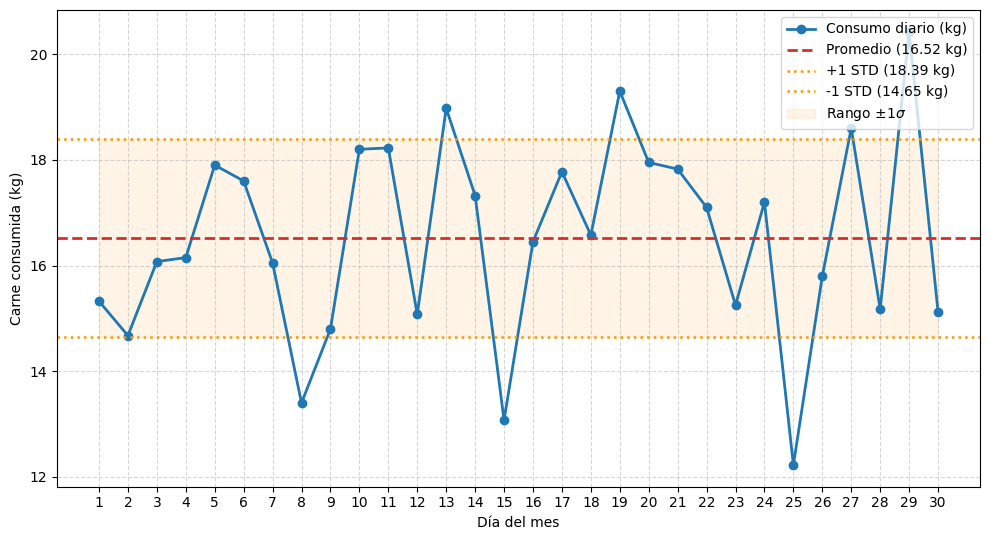

In [ ]:
# ==========================================
# 1. PARÁMETROS DE CARNE Y PRECIOS
# ==========================================
np.random.seed(130)

g_clasica = 125
premium = 200
doble_carne = g_clasica * 2  # 250 gramos
consumo = [g_clasica, premium, doble_carne]
p_hamburguer = [0.5, 0.3, 0.2]

horas_al_dia = 5
max_clientes_por_hora = 30
dias_primer_mes = 30

# ==========================================
# 2. SIMULACIÓN DEL MES
# ==========================================
consumo_diario_sim1 = []

for dia in range(dias_primer_mes):
    consumo_dia = 0
    for hora in range(horas_al_dia):
        num_clientes = np.random.normal(loc=20, scale=5, size=1)
        num_clientes = int(num_clientes[0])
        num_clientes = min(num_clientes, max_clientes_por_hora)
        if num_clientes > 0:
            consumo_actual = np.random.choice(consumo, p=p_hamburguer, size=num_clientes)
            consumo_dia += consumo_actual.sum()
    consumo_diario_sim1.append(consumo_dia)

# Convertir consumo a kilogramos
consumo_diario_kg = [g / 1000 for g in consumo_diario_sim1]

# Cálculo de la media y desviación estándar
promedio_diario_kg = np.mean(consumo_diario_kg)
std_diario_kg = np.std(consumo_diario_kg)

# ==========================================
# 3. GRÁFICO CON MEDIA Y DESTELLOS DE STD
# ==========================================
dias = np.arange(1, dias_primer_mes + 1)

plt.figure(figsize=(10, 5.5))

# Serie de consumo real
plt.plot(dias, consumo_diario_kg, marker='o', color='#1f77b4', linewidth=2, label='Consumo diario (kg)')

# Línea de media diaria
plt.axhline(y=promedio_diario_kg, color='#d32f2f', linestyle='--', linewidth=2,
            label=f'Promedio ({promedio_diario_kg:.2f} kg)')

# Líneas de +1 STD y -1 STD
plt.axhline(y=promedio_diario_kg + std_diario_kg, color='#ff9800', linestyle=':', linewidth=1.8,
            label=f'+1 STD ({promedio_diario_kg + std_diario_kg:.2f} kg)')

plt.axhline(y=promedio_diario_kg - std_diario_kg, color='#ff9800', linestyle=':', linewidth=1.8,
            label=f'-1 STD ({promedio_diario_kg - std_diario_kg:.2f} kg)')

# Banda visual que abarca la primera desviación estándar
plt.fill_between(dias, promedio_diario_kg - std_diario_kg, promedio_diario_kg + std_diario_kg,
                 color='#ff9800', alpha=0.1, label='Rango $\pm 1 \sigma$')

#plt.title('Consumo Diario de Carne: Promedio y Desviación Estándar ($\pm 1 \sigma$)')
plt.xlabel('Día del mes')
plt.ylabel('Carne consumida (kg)')
plt.xticks(dias)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.savefig('c1_consumo_mes.png')
plt.show()

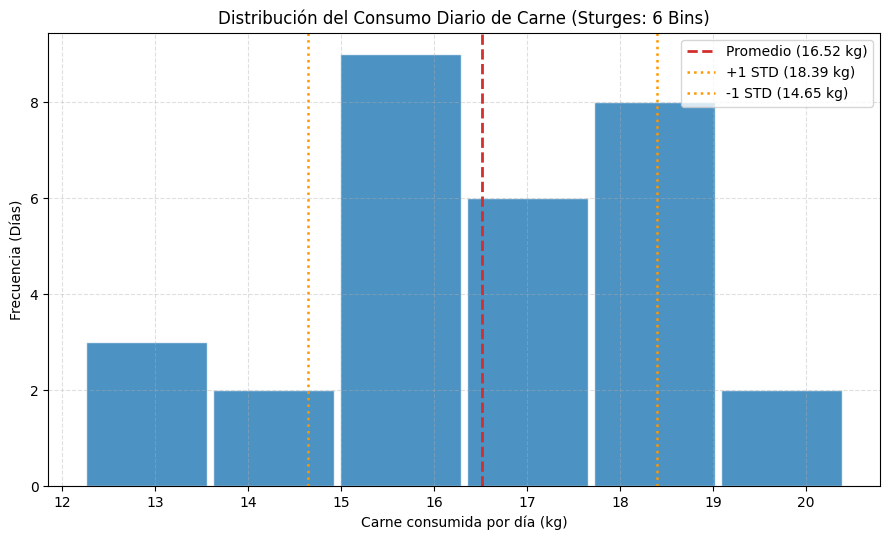

In [ ]:
# Cálculo explícito de Bins con la Regla de Sturges
n = len(consumo_diario_kg)
num_bins_sturges = int(np.ceil(np.log2(n))) + 1  # k = 6 para n = 30
# ==========================================
# 2. HISTOGRAMA CON REGLA DE STURGES
# ==========================================
plt.figure(figsize=(9, 5.5))

# Histograma usando Sturges
n_frec, bins_edges, patches = plt.hist(
    consumo_diario_kg,
    bins='sturges',
    color='#1f77b4',
    edgecolor='white',
    alpha=0.8,
    rwidth=0.95
)

# Línea vertical para la media
plt.axvline(promedio_diario_kg, color='#d32f2f', linestyle='--', linewidth=2,
            label=f'Promedio ({promedio_diario_kg:.2f} kg)')

# Líneas verticales para +/- 1 Desviación Estándar
plt.axvline(promedio_diario_kg + std_diario_kg, color='#ff9800', linestyle=':', linewidth=1.8,
            label=f'+1 STD ({promedio_diario_kg + std_diario_kg:.2f} kg)')

plt.axvline(promedio_diario_kg - std_diario_kg, color='#ff9800', linestyle=':', linewidth=1.8,
            label=f'-1 STD ({promedio_diario_kg - std_diario_kg:.2f} kg)')

# Detalles estéticos y etiquetas
plt.title(f'Distribución del Consumo Diario de Carne (Sturges: {num_bins_sturges} Bins)')
plt.xlabel('Carne consumida por día (kg)')
plt.ylabel('Frecuencia (Días)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('c1_consumo_mes_hist.png')
plt.show()

In [ ]:
# ==========================================
# 1. PARÁMETROS DE CARNE Y PRECIOS
# ==========================================
# semilla
np.random.seed(130)

g_clasica = 125
premium = 200
doble_carne = g_clasica * 2  # 250 gramos
consumo = [g_clasica, premium, doble_carne]
p_hamburguer = [0.5, 0.3, 0.2]

# Precio base por kilo de carne (por ejemplo, 10 dólares)
precio_kilo_carne = 10.0
precio_gramo_carne = precio_kilo_carne / 1000

# El valor de la carne equivale al 20% del precio final (multiplicamos el costo de la carne por 5)
precios_hamburguesas = {
    g_clasica: (g_clasica * precio_gramo_carne) / 0.20,
    premium: (premium * precio_gramo_carne) / 0.20,
    doble_carne: (doble_carne * precio_gramo_carne) / 0.20
}

# Parámetros operativos del local
horas_al_dia = 5
max_clientes_por_hora = 30
dias_primer_mes = 30

# ==========================================
# 2. PRIMERA SIMULACIÓN: LÍNEA DE BASE
# ==========================================
consumo_diario_sim1 = []

for dia in range(dias_primer_mes):
    consumo_dia = 0
    for hora in range(horas_al_dia):
        # Clientes por hora (de 0 a 30 clientes)
        num_clientes = np.random.normal(loc=20, scale=5, size=1)
        num_clientes = int(num_clientes[0])
        num_clientes = min(num_clientes, max_clientes_por_hora)
        if num_clientes > 0:
            consumo_actual = np.random.choice(consumo, p=p_hamburguer, size=num_clientes)
            consumo_dia += consumo_actual.sum()
    consumo_diario_sim1.append(consumo_dia)

# Estadísticos diarios obtenidos
media_diaria = np.mean(consumo_diario_sim1)
std_diaria = np.std(consumo_diario_sim1)

In [ ]:
media_diaria

np.float64(16520.833333333332)

In [ ]:
std_diaria

np.float64(1873.3112765605422)

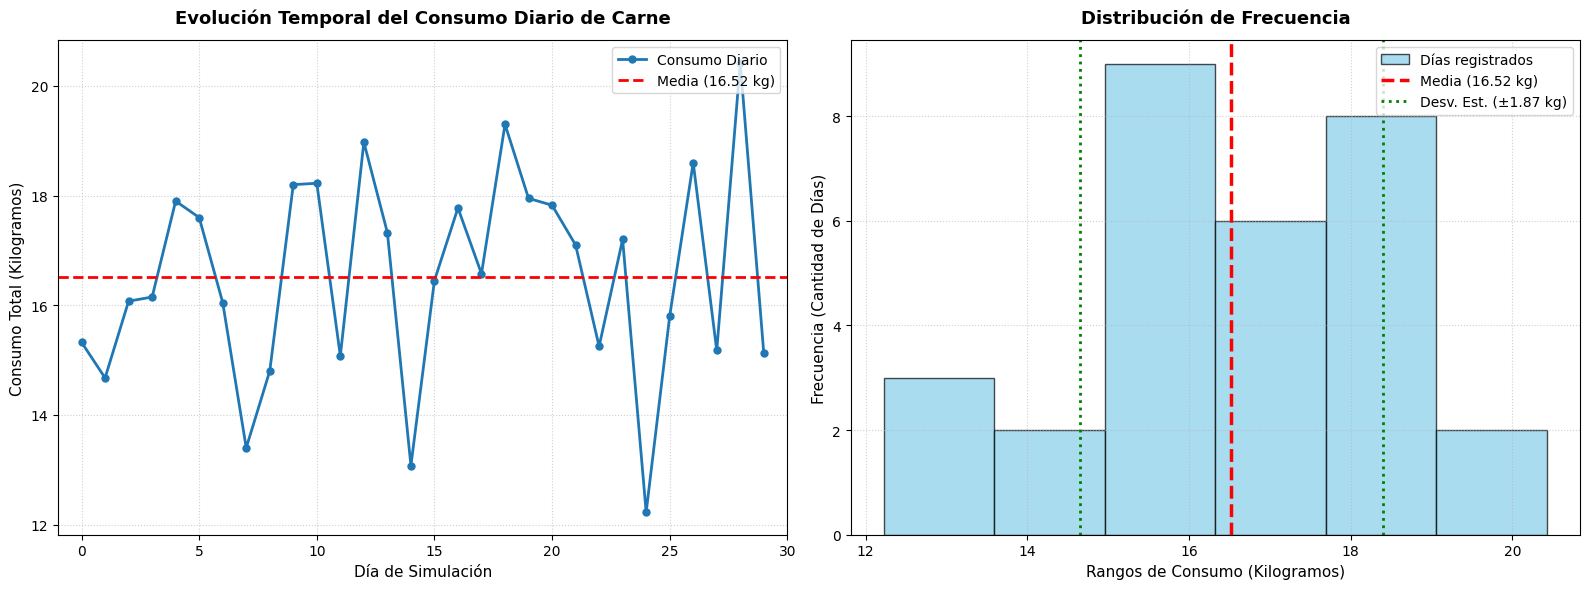

In [ ]:
# 1. Transformar los datos de la primera simulación a kilogramos
datos_kg = np.array(consumo_diario_sim1) / 1000

# Calcular métricas clave en kilogramos
media_kg = np.mean(datos_kg)
std_kg = np.std(datos_kg)

# Calcular el número de intervalos óptimo usando la Regla de Sturges
# k = 1 + log2(N), y redondeamos hacia arriba
num_bins = int(np.ceil(1 + np.log2(len(datos_kg))))

# 2. Configurar el lienzo para albergar dos gráficos (1 fila, 2 columnas)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ========================================================
# GRÁFICO 1: LÍNEA DE TIEMPO (EVOLUCIÓN DIARIA)
# ========================================================
ax1.plot(datos_kg, marker='o', color='#1f77b4', linestyle='-', linewidth=2, markersize=5, label='Consumo Diario')
# Agregar una línea horizontal de referencia para la media
ax1.axhline(media_kg, color='red', linestyle='--', linewidth=2, label=f'Media ({media_kg:.2f} kg)')

ax1.set_title('Evolución Temporal del Consumo Diario de Carne', fontsize=13, pad=12, fontweight='bold')
ax1.set_xlabel('Día de Simulación', fontsize=11)
ax1.set_ylabel('Consumo Total (Kilogramos)', fontsize=11)
ax1.set_xlim(-1, len(datos_kg))
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right')

# ========================================================
# GRÁFICO 2: HISTOGRAMA DE DISTRIBUCIÓN (REGLA DE STURGES)
# ========================================================
# Dibujamos el histograma utilizando los bins calculados por Sturges
ax2.hist(datos_kg, bins=num_bins, color='skyblue', edgecolor='black', alpha=0.7, label='Días registrados')

# Línea vertical para la media
ax2.axvline(media_kg, color='red', linestyle='--', linewidth=2.5, label=f'Media ({media_kg:.2f} kg)')

# Líneas verticales para la desviación estándar (Media +- Desviación Estándar)
ax2.axvline(media_kg + std_kg, color='green', linestyle=':', linewidth=2, label=f'Desv. Est. (±{std_kg:.2f} kg)')
ax2.axvline(media_kg - std_kg, color='green', linestyle=':', linewidth=2)

ax2.set_title(f'Distribución de Frecuencia', fontsize=13, pad=12, fontweight='bold')
ax2.set_xlabel('Rangos de Consumo (Kilogramos)', fontsize=11)
ax2.set_ylabel('Frecuencia (Cantidad de Días)', fontsize=11)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right')

# 3. Ajustar espacios y mostrar/guardar
plt.tight_layout()
plt.savefig('analisis_consumo_linea_base.png', dpi=300)
plt.show()

In [ ]:
# ==========================================
# 3. APLICACIÓN DEL ESTIMADOR DE COMPRA
# ==========================================
gramos_semanales_teoricos = media_diaria * 7
# Compra de kilos enteros redondeando hacia abajo
kilos_a_comprar = math.floor(gramos_semanales_teoricos / 1000)
gramos_comprados_semana = kilos_a_comprar * 1000
costo_compra_semanal = kilos_a_comprar * precio_kilo_carne

In [ ]:
# ==========================================
# 4. SEGUNDA SIMULACIÓN: MONITOREO DE STOCK
# ==========================================
semanas_sim2 = 4 * 12
reporte_semanal = []

for sem in range(1, semanas_sim2 + 1):
    inventario = gramos_comprados_semana
    falto_carne = False
    dia_falto = None
    hora_falto = None
    ingresos_semana = 0

    for d in range(1, 8):  # 7 días de la semana
        for h in range(1, horas_al_dia + 1):  # 5 horas al día
            num_clientes = np.random.normal(loc=20, scale=5, size=1)
            num_clientes = int(num_clientes[0])
            num_clientes = min(max_clientes_por_hora, num_clientes)
            if num_clientes > 0:
                consumo_clientes = np.random.choice(consumo, p=p_hamburguer, size=num_clientes)

                for c_gramos in consumo_clientes:
                    if inventario >= c_gramos:
                        inventario -= c_gramos
                        ingresos_semana += precios_hamburguesas[c_gramos]
                    else:
                        # Si no hay suficiente carne en inventario ocurre un quiebre de stock
                        if not falto_carne:
                            falto_carne = True
                            dia_falto = d
                            hora_falto = h
                        # El inventario llega a cero y no se pueden procesar más ventas
                        inventario = 0

    reporte_semanal.append({
        "Semana": sem,
        "Kilos Comprados": kilos_a_comprar,
        "Costo Compra ($)": costo_compra_semanal,
        "Ingresos Ventas ($)": ingresos_semana,
        "Ganancia neta ($)": ingresos_semana - costo_compra_semanal,
        "Sobrante Final (g)": inventario,
        "¿Faltó Carne?": "Sí" if falto_carne else "No",
        "Día del Quiebre": dia_falto if falto_carne else "-",
        "Hora del Quiebre": hora_falto if falto_carne else "-"
    })

# Convertir los resultados en DataFrame para el reporte final
df_reporte = pd.DataFrame(reporte_semanal)

# Guardamos los resultados en un archivo CSV para mantener el registro
df_reporte.to_csv("reporte_simulacion_hamburguesas.csv", index=False)

# ==========================================
# 5. REPORTE FINAL EN CONSOLA
# ==========================================
print("==================================================")
print("       REPORTE DE SIMULACIÓN COMERCIAL            ")
print("==================================================")
print("\n[1] ESTRUCTURA DE PRECIOS CALCULADA:")
print(f"  * Hamburguesa Clásica (125g):    ${precios_hamburguesas[g_clasica]:.2f}")
print(f"  * Hamburguesa Premium (200g):    ${precios_hamburguesas[premium]:.2f}")
print(f"  * Hamburguesa Doble Carne (250g): ${precios_hamburguesas[doble_carne]:.2f}")

print("\n[2] ANÁLISIS DE CONSUMO (SIMULACIÓN 1):")
print(f"  * Media de consumo diario:       {media_diaria:.2f} gramos")
print(f"  * Desviación estándar diaria:    {std_diaria:.2f} gramos")
print(f"  * Meta teórica semanal calculada: {gramos_semanales_teoricos:.2f} gramos")
print(f"  * Kilos a comprar (Ajustado desc.): {kilos_a_comprar} kg por semana ({gramos_comprados_semana} gramos)")

print("\n[3] EVALUACIÓN DE INVENTARIO EN ESCENARIO REAL (SIMULACIÓN 2):")
print(df_reporte.to_string(index=False))
print("==================================================")

       REPORTE DE SIMULACIÓN COMERCIAL            

[1] ESTRUCTURA DE PRECIOS CALCULADA:
  * Hamburguesa Clásica (125g):    $6.25
  * Hamburguesa Premium (200g):    $10.00
  * Hamburguesa Doble Carne (250g): $12.50

[2] ANÁLISIS DE CONSUMO (SIMULACIÓN 1):
  * Media de consumo diario:       16520.83 gramos
  * Desviación estándar diaria:    1873.31 gramos
  * Meta teórica semanal calculada: 115645.83 gramos
  * Kilos a comprar (Ajustado desc.): 115 kg por semana (115000 gramos)

[3] EVALUACIÓN DE INVENTARIO EN ESCENARIO REAL (SIMULACIÓN 2):
 Semana  Kilos Comprados  Costo Compra ($)  Ingresos Ventas ($)  Ganancia neta ($)  Sobrante Final (g) ¿Faltó Carne? Día del Quiebre Hora del Quiebre
      1              115            1150.0              5746.25            4596.25                   0            Sí               7                4
      2              115            1150.0              5750.00            4600.00                   0            Sí               7                5
    

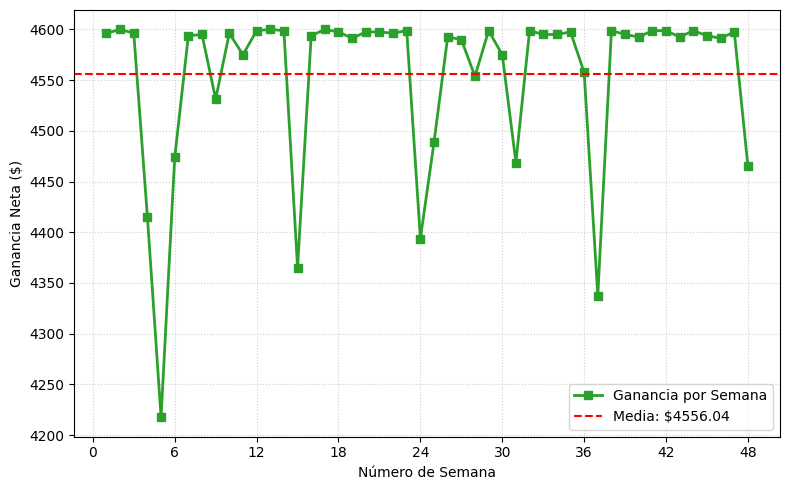

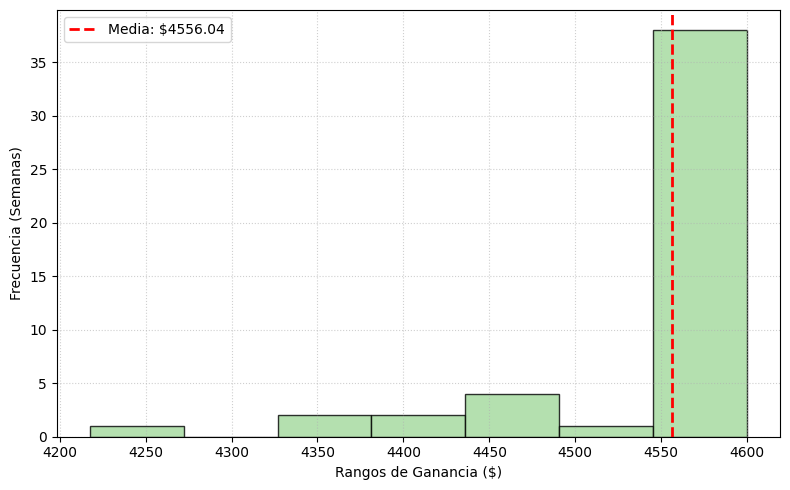

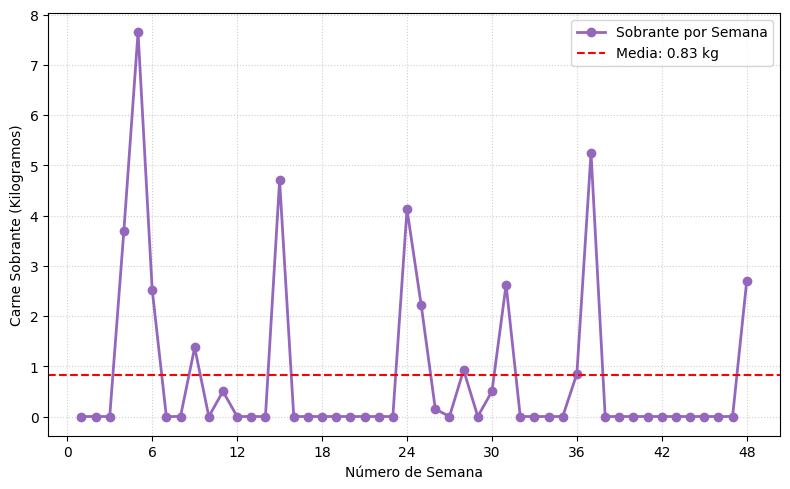

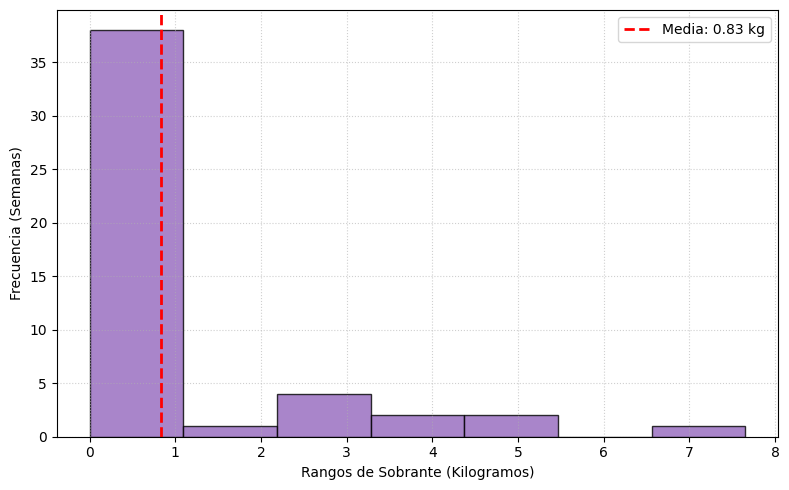

In [ ]:
# Conversión y preparación de variables
df_reporte['Sobrante Final (kg)'] = df_reporte['Sobrante Final (g)'] / 1000

# Número de bins óptimo por Sturges (mínimo 3)
n_elementos = len(df_reporte)
num_bins = max(3, int(np.ceil(1 + np.log2(n_elementos))))

# Medias
media_ganancia = df_reporte['Ganancia neta ($)'].mean()
media_sobrante_kg = df_reporte['Sobrante Final (kg)'].mean()

# =====================================================================
# FIGURA 1: EVOLUCIÓN DE LA GANANCIA NETA
# =====================================================================
fig1, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(df_reporte['Semana'], df_reporte['Ganancia neta ($)'], marker='s', color='#2ca02c', linewidth=2, label='Ganancia por Semana')
ax1.axhline(media_ganancia, color='red', linestyle='--', linewidth=1.5, label=f'Media: ${media_ganancia:.2f}')
ax1.set_xlabel('Número de Semana', fontsize=10)
ax1.set_ylabel('Ganancia Neta ($)', fontsize=10)
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

plt.tight_layout()
plt.savefig('c2_ganancia_evolucion.png', dpi=300)
plt.show()
plt.close(fig1)

# =====================================================================
# FIGURA 2: DISTRIBUCIÓN DE LA GANANCIA NETA
# =====================================================================
fig2, ax2 = plt.subplots(figsize=(8, 5))

ax2.hist(df_reporte['Ganancia neta ($)'], bins=num_bins, color='#a1d99b', edgecolor='black', alpha=0.8)
ax2.axvline(media_ganancia, color='red', linestyle='--', linewidth=2, label=f'Media: ${media_ganancia:.2f}')
ax2.set_xlabel('Rangos de Ganancia ($)', fontsize=10)
ax2.set_ylabel('Frecuencia (Semanas)', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('c2_ganancia_distribucion.png', dpi=300)
plt.show()

plt.close(fig2)

# =====================================================================
# FIGURA 3: EVOLUCIÓN DEL SOBRANTE DE CARNE
# =====================================================================
fig3, ax3 = plt.subplots(figsize=(8, 5))

ax3.plot(df_reporte['Semana'], df_reporte['Sobrante Final (kg)'], marker='o', color='#9467bd', linewidth=2, label='Sobrante por Semana')
ax3.axhline(media_sobrante_kg, color='red', linestyle='--', linewidth=1.5, label=f'Media: {media_sobrante_kg:.2f} kg')
#ax3.set_title('Evolución del Sobrante de Carne al Final de la Semana', fontsize=12, fontweight='bold')
ax3.set_xlabel('Número de Semana', fontsize=10)
ax3.set_ylabel('Carne Sobrante (Kilogramos)', fontsize=10)
ax3.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.legend()

plt.tight_layout()
plt.savefig('c2_sobrante_evolucion.png', dpi=300)
plt.show()

plt.close(fig3)

# =====================================================================
# FIGURA 4: DISTRIBUCIÓN DEL SOBRANTE DE CARNE
# =====================================================================
fig4, ax4 = plt.subplots(figsize=(8, 5))

ax4.hist(df_reporte['Sobrante Final (kg)'], bins=num_bins, color='#9467bd', edgecolor='black', alpha=0.8)
ax4.axvline(media_sobrante_kg, color='red', linestyle='--', linewidth=2, label=f'Media: {media_sobrante_kg:.2f} kg')
#ax4.set_title('Distribución del Stock Sobrante', fontsize=12, fontweight='bold')
ax4.set_xlabel('Rangos de Sobrante (Kilogramos)', fontsize=10)
ax4.set_ylabel('Frecuencia (Semanas)', fontsize=10)
ax4.grid(True, linestyle=':', alpha=0.6)
ax4.legend()

plt.tight_layout()
plt.savefig('c2_sobrante_distribucion.png', dpi=300)
plt.show()
plt.close(fig4)

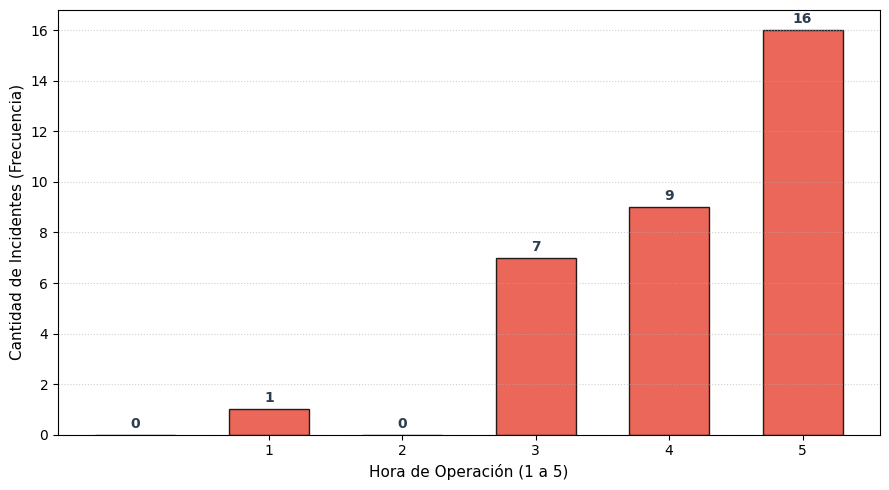

In [ ]:
# 1. Contar cuántos quiebres ocurrieron en cada hora (del 1 al 5)
# .reindex asegura que se muestren las 5 horas, incluso si alguna tuvo cero quiebres
conteo_horas = df_reporte['Hora del Quiebre'].value_counts().reindex(range(1, 6), fill_value=0)

# 2. Configurar el diseño del gráfico
plt.figure(figsize=(9, 5))

# Crear el gráfico de barras con un color de advertencia (rojo suave)
barras = plt.bar(conteo_horas.index, conteo_horas.values, color='#e74c3c', edgecolor='black', alpha=0.85, width=0.6)

# 3. Agregar el valor exacto encima de cada barra para facilitar la lectura
for barra in barras:
    altura = barra.get_height()
    plt.annotate(f'{int(altura)}',
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 3),  # Desplazamiento de 3 puntos hacia arriba
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='bold', color='#2c3e50')

# 4. Personalizar títulos y etiquetas
#plt.title('Distribución de Quiebres de Stock por Hora de Operación', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Hora de Operación (1 a 5)', fontsize=11)
plt.ylabel('Cantidad de Incidentes (Frecuencia)', fontsize=11)

# Asegurar que el eje X solo muestre los números enteros del 1 al 5
plt.xticks(range(1, 6))

# Añadir líneas de cuadrícula horizontales sutiles
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Ajustar márgenes y guardar la imagen
plt.tight_layout()
plt.savefig('c2_quiebres_por_hora_barras.png', dpi=300)
plt.show()

## Escenario Extremistán

In [ ]:
# Parámetros base
horas_al_dia = 5
media_clientes_hora = 150
std_clientes_hora = 20
dias_mes = 30
peso_hamburguesa_normal = 125 # gramos
precio_kilo_carne = 10.0 # dólares

# El costo de la carne (125g = 0.125kg * $10 = $1.25) es el 20% del precio final
precio_venta_hamburguesa = (peso_hamburguesa_normal / 1000 * precio_kilo_carne) / 0.20 # $6.25

In [ ]:
# =====================================================================
# PARTE 1: LA FALACIA DEL PROMEDIO (SIMULACIÓN DE 1 MES)
# =====================================================================
# semilla
np.random.seed(130)

cadenas = ["McDonald's", "Burger King", "Wendy's"]
independientes_p1 = [f"Local Independiente {i}" for i in range(1, 28)]
locales_p1 = cadenas + independientes_p1

# Probabilidades de la regla 80/20
p_cadenas_p1 = 0.80 / len(cadenas)
p_indep_p1 = 0.20 / len(independientes_p1)
probabilidades_p1 = [p_cadenas_p1] * 3 + [p_indep_p1] * 27

# Matriz para contar pedidos diarios (30 días x 30 locales)
pedidos_diarios_p1 = np.zeros((dias_mes, len(locales_p1)))

for dia in range(dias_mes):
    for hora in range(horas_al_dia):
        # Distribución normal de clientes por hora
        clientes_hora = max(0, int(np.round(np.random.normal(media_clientes_hora, std_clientes_hora))))
        if clientes_hora > 0:
            elecciones = np.random.choice(locales_p1, size=clientes_hora, p=probabilidades_p1)
            for local in elecciones:
                idx = locales_p1.index(local)
                pedidos_diarios_p1[dia, idx] += 1

# Cálculos de promedios diarios globales e internos
total_pedidos_mes = pedidos_diarios_p1.sum()
promedio_diario_global_app = total_pedidos_mes / dias_mes
promedio_enganoso_por_local = promedio_diario_global_app / len(locales_p1)

# Datos ocultos (reales por segmento)
promedio_real_cadenas = pedidos_diarios_p1[:, :3].sum() / dias_mes / 3
promedio_real_independientes = pedidos_diarios_p1[:, 3:].sum() / dias_mes / 27

print("=====================================================================")
print("PARTE 1: EL REPORTE ENGAÑOSO DE LA APP")
print("=====================================================================")
print(f"Pedidos diarios totales en la App (Promedio): {promedio_diario_global_app:.2f}")
print(f"MÉTRICA PÚBLICA (Promedio Engañoso por Local): {promedio_enganoso_por_local:.2f} pedidos/día")
print("\n--- LO QUE SUCEDE OCULTAMENTE ---")
print(f"Promedio Real de cada Cadena Famosa:          {promedio_real_cadenas:.2f} pedidos/día")
print(f"Promedio Real de cada Local Independiente:   {promedio_real_independientes:.2f} pedidos/día")
print("=====================================================================\n")

PARTE 1: EL REPORTE ENGAÑOSO DE LA APP
Pedidos diarios totales en la App (Promedio): 743.00
MÉTRICA PÚBLICA (Promedio Engañoso por Local): 24.77 pedidos/día

--- LO QUE SUCEDE OCULTAMENTE ---
Promedio Real de cada Cadena Famosa:          198.70 pedidos/día
Promedio Real de cada Local Independiente:   5.44 pedidos/día



In [ ]:
743/30

24.766666666666666

In [ ]:
len(locales_p1)

30

In [ ]:
5.44*7

38.080000000000005

In [ ]:
promedio_enganoso_por_local

np.float64(24.766666666666666)

In [ ]:
int(promedio_enganoso_por_local)

24

In [ ]:
# =====================================================================
# PARTE 2: LA LLEGADA DEL NUEVO LOCAL INGENUO (SIMULACIÓN DE 4 SEMANAS)
# =====================================================================

# El nuevo local planifica su stock semanal usando el promedio engañoso
pedidos_semanales_estimados = int(promedio_enganoso_por_local) * 7
gramos_carne_necesarios = pedidos_semanales_estimados * peso_hamburguesa_normal
# Compra en kilos enteros (usamos floor / hacia abajo como regla establecida)
kilos_a_comprar_semanal = math.floor(gramos_carne_necesarios / 1000)
gramos_comprados_semana = kilos_a_comprar_semanal * 1000
costo_semanal_carne = kilos_a_comprar_semanal * precio_kilo_carne

# Configuración del nuevo mercado (Ahora son 28 independientes, 31 locales en total)
independientes_p2 = independientes_p1 + ["Nuevo Local Ingenuo"]
locales_p2 = cadenas + independientes_p2

p_cadenas_p2 = 0.80 / len(cadenas)
p_indep_p2 = 0.20 / len(independientes_p2) # El 20% se divide ahora para 28
probabilidades_p2 = [p_cadenas_p2] * 3 + [p_indep_p2] * 28

semanas_p2 = 4 * 2
reporte_nuevo_local = []

for sem in range(1, semanas_p2 + 1):
    inventario_carne = gramos_comprados_semana
    pedidos_recibidos = 0
    pedidos_perdidos_stock = 0

    for d in range(7):
        for h in range(horas_al_dia):
            clientes_hora = max(0, int(np.round(np.random.normal(media_clientes_hora, std_clientes_hora))))
            if clientes_hora > 0:
                elecciones = np.random.choice(locales_p2, size=clientes_hora, p=probabilidades_p2)

                # Contar cuántos de esos clientes eligieron al "Nuevo Local Ingenuo"
                pedidos_para_mi = np.sum(elecciones == "Nuevo Local Ingenuo")

                for _ in range(pedidos_para_mi):
                    if inventario_carne >= peso_hamburguesa_normal:
                        inventario_carne -= peso_hamburguesa_normal
                        pedidos_recibidos += 1
                    else:
                        pedidos_perdidos_stock += 1

    # Finanzas de la semana
    ingresos = pedidos_recibidos * precio_venta_hamburguesa
    ganancia_neta = ingresos - costo_semanal_carne
    sobrante_kg = inventario_carne / 1000

    reporte_nuevo_local.append({
        "Semana": sem,
        "Kilos Comprados": kilos_a_comprar_semanal,
        "Costo Carne ($)": costo_semanal_carne,
        "Pedidos Vendidos": pedidos_recibidos,
        "Ingresos ($)": ingresos,
        "Ganancia Neta ($)": ganancia_neta,
        "Carne Sobrante (kg)": sobrante_kg
    })

df_tragedia = pd.DataFrame(reporte_nuevo_local)

print("=====================================================================")
print("PARTE 2: ECONOMÍA DEL NUEVO LOCAL (TRAS 4 SEMANAS DE INGENUIDAD)")
print("=====================================================================")
print(f"Planificación basada en creer que vendería: {pedidos_semanales_estimados:.1f} hamburguesas/semana")
print(f"Compra fija semanal: {kilos_a_comprar_semanal} kg de carne (Inversión: ${costo_semanal_carne:.2f}/sem)")
print("---------------------------------------------------------------------")
print(df_tragedia.to_string(index=False))
print("=====================================================================")

# Balance consolidado
total_perdido = df_tragedia["Ganancia Neta ($)"].sum()
print(f"Balance económico total: ${total_perdido:.2f}")

PARTE 2: ECONOMÍA DEL NUEVO LOCAL (TRAS 4 SEMANAS DE INGENUIDAD)
Planificación basada en creer que vendería: 168.0 hamburguesas/semana
Compra fija semanal: 21 kg de carne (Inversión: $210.00/sem)
---------------------------------------------------------------------
 Semana  Kilos Comprados  Costo Carne ($)  Pedidos Vendidos  Ingresos ($)  Ganancia Neta ($)  Carne Sobrante (kg)
      1               21            210.0                43        268.75              58.75               15.625
      2               21            210.0                32        200.00             -10.00               17.000
      3               21            210.0                37        231.25              21.25               16.375
      4               21            210.0                26        162.50             -47.50               17.750
      5               21            210.0                39        243.75              33.75               16.125
      6               21            210.0         

In [ ]:
125 * 168

21000

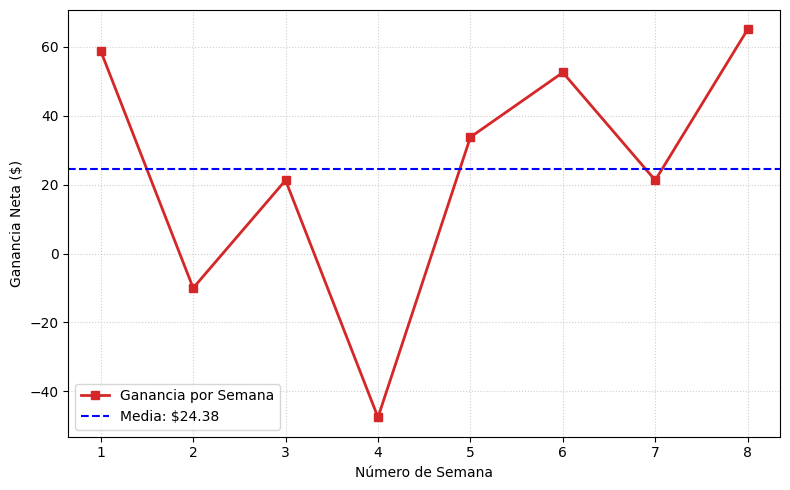

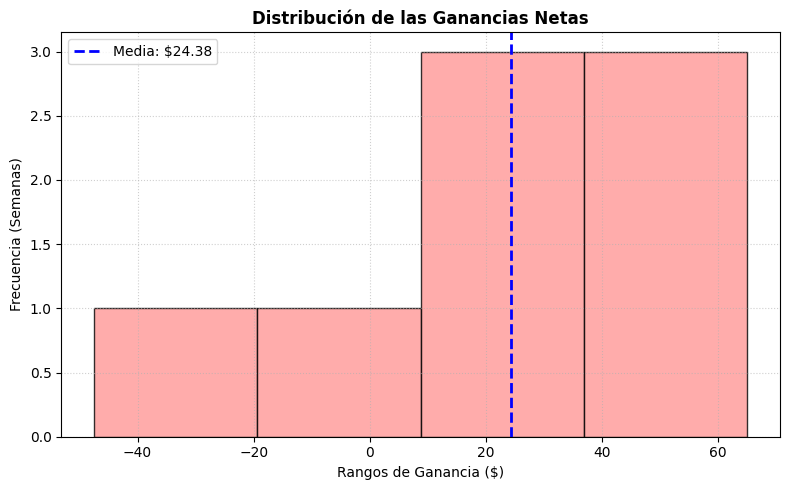

In [ ]:
# 1. Configurar el número de bins óptimo por Sturges (mínimo 3 bins para muestras pequeñas)
n_elementos = len(df_tragedia)
num_bins = max(3, int(np.ceil(1 + np.log2(n_elementos))))

media_ganancia = df_tragedia['Ganancia Neta ($)'].mean()

# =====================================================================
# GRÁFICO 1: Línea de tiempo
# =====================================================================
fig1, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(df_tragedia['Semana'], df_tragedia['Ganancia Neta ($)'], marker='s', color='#d62728', linewidth=2, label='Ganancia por Semana')
ax1.axhline(media_ganancia, color='blue', linestyle='--', linewidth=1.5, label=f'Media: ${media_ganancia:.2f}')
#ax1.set_title('Evolución de la Ganancia Neta Semanal (Escenario Ingenuo)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Número de Semana', fontsize=10)
ax1.set_ylabel('Ganancia Neta ($)', fontsize=10)

# Localizador inteligente para evitar amontonamiento en el eje X
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

plt.tight_layout()
plt.savefig('c2_tragedia_linea_tiempo.png', dpi=300)
plt.show()
plt.close(fig1)

# =====================================================================
# GRÁFICO 2: Histograma de distribución
# =====================================================================
fig2, ax2 = plt.subplots(figsize=(8, 5))

ax2.hist(df_tragedia['Ganancia Neta ($)'], bins=num_bins, color='#ff9896', edgecolor='black', alpha=0.8)
ax2.axvline(media_ganancia, color='blue', linestyle='--', linewidth=2, label=f'Media: ${media_ganancia:.2f}')
ax2.set_title('Distribución de las Ganancias Netas', fontsize=12, fontweight='bold')
ax2.set_xlabel('Rangos de Ganancia ($)', fontsize=10)
ax2.set_ylabel('Frecuencia (Semanas)', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('c2_tragedia_histograma.png', dpi=300)
plt.show()
plt.close(fig2)

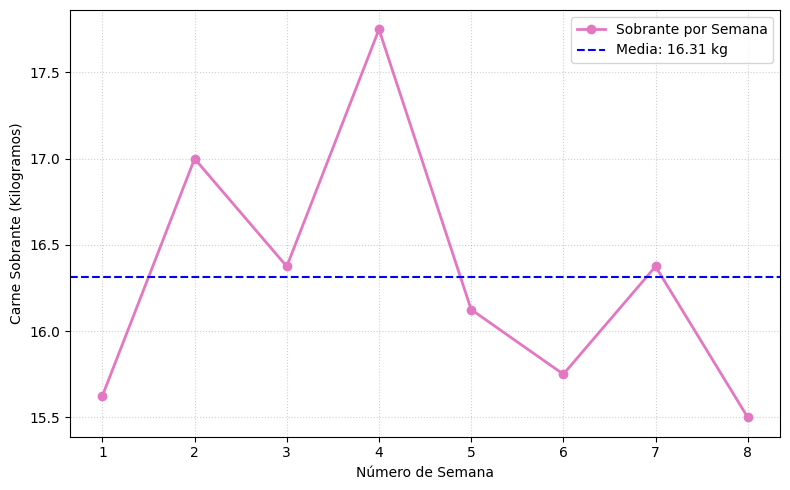

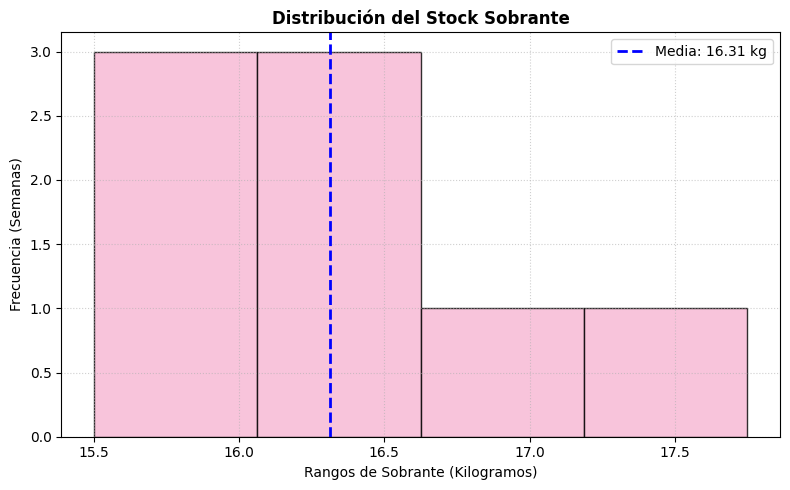

In [ ]:
# =====================================================================
# REPORTE DE CARNE SOBRANTE (Separado en 2 gráficos independientes)
# =====================================================================
media_sobrante_kg = df_tragedia['Carne Sobrante (kg)'].mean()

# ---------------------------------------------------------------------
# GRÁFICO 1: Línea de tiempo
# ---------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(df_tragedia['Semana'], df_tragedia['Carne Sobrante (kg)'], marker='o', color='#e377c2', linewidth=2, label='Sobrante por Semana')
ax1.axhline(media_sobrante_kg, color='blue', linestyle='--', linewidth=1.5, label=f'Media: {media_sobrante_kg:.2f} kg')
#ax1.set_title('Evolución del Sobrante de Carne (Escenario Ingenuo)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Número de Semana', fontsize=10)
ax1.set_ylabel('Carne Sobrante (Kilogramos)', fontsize=10)

# Localizador inteligente para evitar amontonamiento en el eje X
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

plt.tight_layout()
plt.savefig('c2_tragedia_linea_tiempo_sobrante.png', dpi=300)
plt.show()  # Despliega el primer gráfico en Colab

# ---------------------------------------------------------------------
# GRÁFICO 2: Histograma
# ---------------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(8, 5))

ax2.hist(df_tragedia['Carne Sobrante (kg)'], bins=num_bins, color='#f7b6d2', edgecolor='black', alpha=0.8)
ax2.axvline(media_sobrante_kg, color='blue', linestyle='--', linewidth=2, label=f'Media: {media_sobrante_kg:.2f} kg')
ax2.set_title('Distribución del Stock Sobrante', fontsize=12, fontweight='bold')
ax2.set_xlabel('Rangos de Sobrante (Kilogramos)', fontsize=10)
ax2.set_ylabel('Frecuencia (Semanas)', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig('c2_tragedia_histograma_sobrante.png', dpi=300)
plt.show()  # Despliega el segundo gráfico en Colab

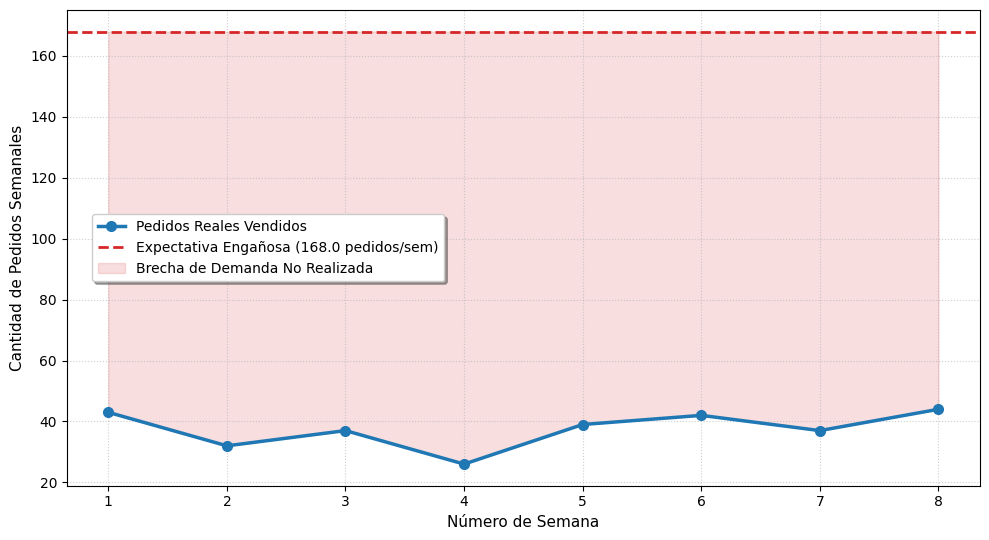

In [ ]:
import matplotlib.pyplot as plt

# Configurar el tamaño y estilo del lienzo
plt.figure(figsize=(10, 5.5))

# 1. Graficar los pedidos reales vendidos por semana
plt.plot(df_tragedia['Semana'], df_tragedia['Pedidos Vendidos'],
         marker='o', color='#1f77b4', linewidth=2.5, markersize=7, label='Pedidos Reales Vendidos')

# 2. Graficar la línea horizontal de la expectativa basada en el promedio engañoso
plt.axhline(pedidos_semanales_estimados, color='#d62728', linestyle='--', linewidth=2,
            label=f'Expectativa Engañosa ({pedidos_semanales_estimados:.1f} pedidos/sem)')

# 3. Sombrear el área entre la expectativa y la realidad para enfatizar la brecha
plt.fill_between(df_tragedia['Semana'], df_tragedia['Pedidos Vendidos'], pedidos_semanales_estimados,
                 color='#d62728', alpha=0.15, label='Brecha de Demanda No Realizada')

# Personalización de títulos, etiquetas y diseño
#plt.title('Expectativa vs. Realidad: Impacto de la Falacia del Promedio', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Número de Semana', fontsize=11)
plt.ylabel('Cantidad de Pedidos Semanales', fontsize=11)

# Forzar a que el eje X muestre solo números enteros de semanas
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(integer=True))

# Añadir rejilla de fondo sutil y ajustar la leyenda
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='center left', bbox_to_anchor=(0.02, 0.5), fontsize=10, frameon=True, shadow=True)

# Ajustar márgenes y guardar la imagen en alta definición
plt.tight_layout()
plt.savefig('c2_expectativa_vs_realidad_pedidos.png', dpi=300)
plt.show()

In [ ]:
!pip install squarify

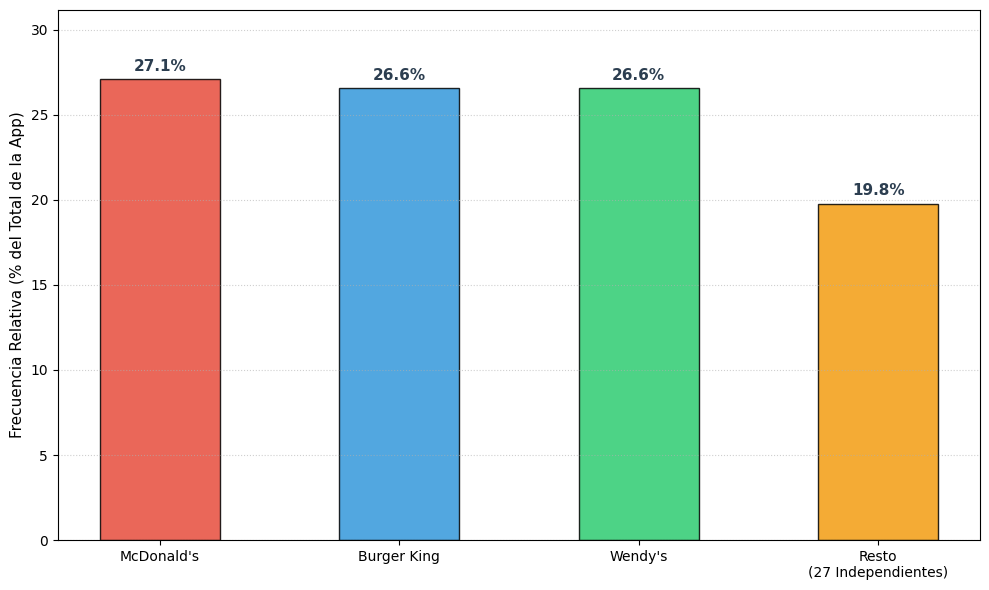

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Agrupar los valores absolutos
total_pedidos_por_local = pedidos_diarios_p1.sum(axis=0)
total_pedidos_mes = total_pedidos_por_local.sum()

valores_absolutos = [
    total_pedidos_por_local[0],        # McDonald's
    total_pedidos_por_local[1],        # Burger King
    total_pedidos_por_local[2],        # Wendy's
    total_pedidos_por_local[3:].sum()  # Suma de los 27 independientes
]

# Convertir los valores a frecuencias relativas (porcentajes)
porcentajes_barras = [(v / total_pedidos_mes) * 100 for v in valores_absolutos]

labels_barras = ["McDonald's", "Burger King", "Wendy's", "Resto\n(27 Independientes)"]
colores = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

# 2. Configurar el lienzo del gráfico
plt.figure(figsize=(10, 6))

# Crear las barras utilizando los porcentajes calculados
barras = plt.bar(labels_barras, porcentajes_barras, color=colores, edgecolor='black', alpha=0.85, width=0.5)

# 3. Agregar la etiqueta del porcentaje exacto encima de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.annotate(f'{altura:.1f}%',
                 xy=(barra.get_x() + barra.get_width() / 2, altura),
                 xytext=(0, 4),  # Desplazamiento de 4 puntos hacia arriba
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2c3e50')

# Personalizar títulos, ejes y formato de porcentaje
#plt.title('Cuota de Mercado Mensual: Cadenas Grandes vs. Resto Agrupado', fontsize=13, pad=15, fontweight='bold')
plt.ylabel('Frecuencia Relativa (% del Total de la App)', fontsize=11)

# Ajustar el límite del eje Y para acomodar los textos de las etiquetas
plt.ylim(0, max(porcentajes_barras) * 1.15)

# Añadir una cuadrícula horizontal sutil
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Optimizar los márgenes y guardar el archivo
plt.tight_layout()
plt.savefig('c2_comparativa_cadenas_vs_resto_porcentajes.png', dpi=300)
plt.show()

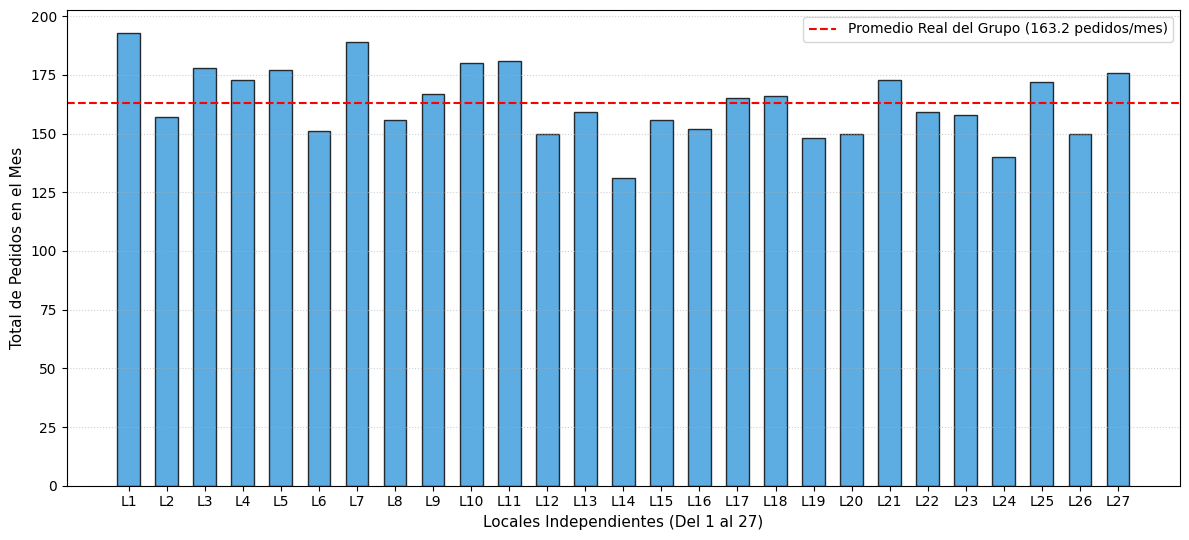

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Extraer los datos acumulados de los 27 locales independientes (del índice 3 en adelante)
pedidos_independientes = pedidos_diarios_p1.sum(axis=0)[3:]

# Creamos etiquetas cortas (L1, L2, ..., L27) para que el eje X se lea de forma limpia
nombres_eje_x = [f"L{i}" for i in range(1, 28)]

# Calcular la media acumulada mensual de este grupo como referencia visual
media_acumulada_grupo = np.mean(pedidos_independientes)

# 2. Configurar el lienzo del gráfico de barras
plt.figure(figsize=(12, 5.5))

# Dibujar las barras clásicas
plt.bar(nombres_eje_x, pedidos_independientes, color='#3498db', edgecolor='black', alpha=0.8, width=0.6)

# Añadir una línea horizontal con el promedio real para darle contexto analítico al gráfico
plt.axhline(media_acumulada_grupo, color='red', linestyle='--', linewidth=1.5,
            label=f'Promedio Real del Grupo ({media_acumulada_grupo:.1f} pedidos/mes)')

# Personalizar títulos y etiquetas de los ejes
#plt.title('Volumen de Pedidos Mensuales por Local Independiente (Excluyendo Franquicias)', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Locales Independientes (Del 1 al 27)', fontsize=11)
plt.ylabel('Total de Pedidos en el Mes', fontsize=11)

# Configurar rejilla de fondo sutil para facilitar la lectura de las alturas
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

# Optimizar espacios y guardar la imagen
plt.tight_layout()
plt.savefig('c2_pedidos_independientes_barras.png', dpi=300)
plt.show()